# Minimum spanning tree (heuristic)

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from scipy.sparse.csgraph import minimum_spanning_tree, connected_components

from sklearn.cluster import AgglomerativeClustering


## Data

In [10]:
k = 3

iris = load_iris()
X_raw = iris.data
y = iris.target
X = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0, ddof=1)

## Minimum spanning tree (MST)

### Edges with `SciPy`

In [11]:
%%time

distance = euclidean_distances(X)
mst = minimum_spanning_tree(distance)

def clusters_mst(mst, k):
    T = mst.toarray()
    edges = np.argwhere(T > 0)
    weights = T[T > 0]
    for idx in np.argsort(weights)[::-1][:k - 1]:   # remove k-1 longest edges
        i, j = edges[idx]
        T[i, j] = 0
    _, labels = connected_components(T, directed=False)
    return labels

labels_heur_mst = clusters_mst(mst, k)

CPU times: user 8.02 ms, sys: 3.54 ms, total: 11.6 ms
Wall time: 9.78 ms


Visualisation (after a PCA) of the edges while displaying the species of iris.

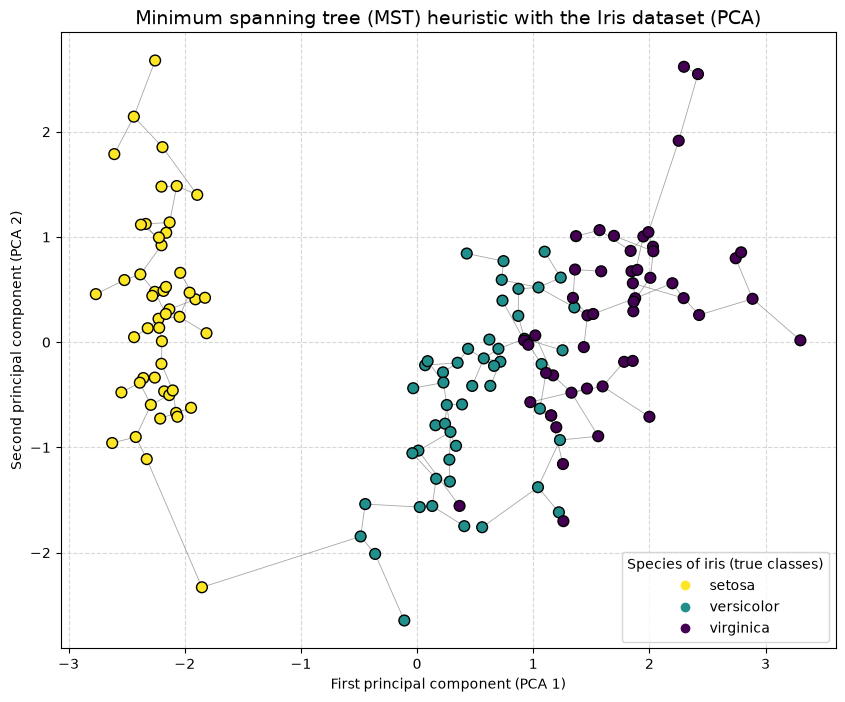

In [12]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

plt.figure(figsize=(10, 8))

rows, cols = mst.nonzero()

for i, j in zip(rows, cols):
  plt.plot(
      [X_2d[i, 0], X_2d[j, 0]],
      [X_2d[i, 1], X_2d[j, 1]],
      color='gray',
      linestyle='-',
      linewidth=0.6,
      alpha=0.7,
  )

scatter = plt.scatter(
    X_2d[:, 0], X_2d[:, 1], c=y, cmap='viridis_r', s=60, edgecolor='k', zorder=3
)
plt.legend(
    handles=scatter.legend_elements()[0],
    labels=list(iris.target_names),
    title="Species of iris (true classes)",
)

plt.title(
    "Minimum spanning tree (MST) heuristic with the Iris dataset (PCA)", fontsize=14
)
plt.xlabel("First principal component (PCA 1)")
plt.ylabel("Second principal component (PCA 2)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig("iris_heuristic_mst.png")
plt.show()

### MST with `sklearn`

The edges from the `SciPy` MST were kept as they result in the same clustering. Here is the visualisation of the affectation to the different cluster:

In [13]:
mst_clustering = AgglomerativeClustering(n_clusters=k, linkage="single")
labels_heur_mst_sklearn = mst_clustering.fit_predict(X)

adjusted_rand_score(labels_heur_mst, labels_heur_mst_sklearn) == 1.0

True

The clusters are the same. To visualise the clusters with the edges:

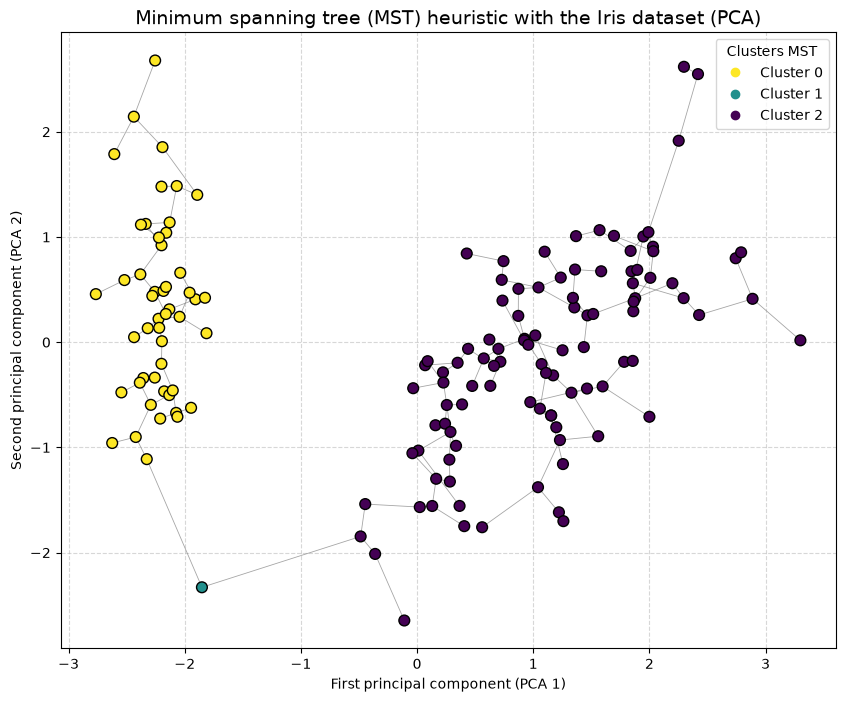

In [14]:

# PCA for visualisation
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

plt.figure(figsize=(10, 8))

# To have the edges of the SciPy MST:
try:
  rows, cols = mst.nonzero()
  for i, j in zip(rows, cols):
    plt.plot(
        [X_2d[i, 0], X_2d[j, 0]],
        [X_2d[i, 1], X_2d[j, 1]],
        color="gray",
        linestyle="-",
        linewidth=0.6,
        alpha=0.7,
    )
except NameError:
  pass

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=labels_heur_mst,
    cmap="viridis_r",
    s=60,
    edgecolor="k",
    zorder=3,
)

plt.legend(
    handles=scatter.legend_elements()[0],
    labels=[f"Cluster {i}" for i in range(k)],
    title="Clusters MST",
)

plt.title(
    "Minimum spanning tree (MST) heuristic with the Iris dataset (PCA)",
    fontsize=14,
)
plt.xlabel("First principal component (PCA 1)")
plt.ylabel("Second principal component (PCA 2)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig("iris_heuristic_mst_clusters.png")
plt.show()